       Measurements  Sample  RSSI_dBm
0     0dBm_messung1       1     -60.0
1     0dBm_messung1       2     -60.0
2     0dBm_messung1       3     -60.0
3     0dBm_messung1       4     -60.0
4     0dBm_messung1       5     -60.0
...             ...     ...       ...
4790  0dBm_messung5     959       NaN
4791  0dBm_messung5     960       NaN
4792  0dBm_messung5     961       NaN
4793  0dBm_messung5     962       NaN
4794  0dBm_messung5     963       NaN

[4795 rows x 3 columns]


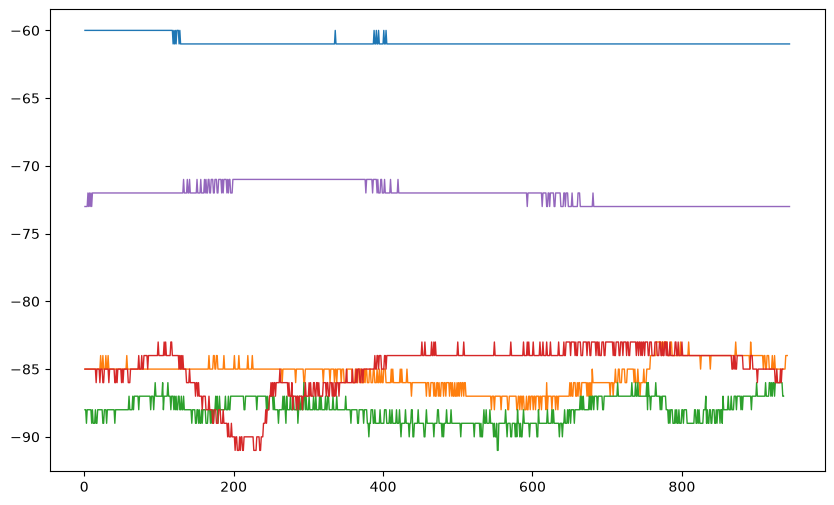

In [22]:
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd
from pathlib import Path

data_dir = Path("./Measurements")
files = sorted(data_dir.glob("0dBm_messung*.txt"))

measurements = [] 

for file in files:
    df = pd.read_csv(file, header=None, names=["raw"], dtype=str)

    df["RSSI_dBm"] = (
        df["raw"]
        .str.extract(r"RX-RSSI=(-?\d+(?:\.\d+)?)", expand=False)
        .astype(float)
    )

    df["Sample"] = np.arange(1, len(df) + 1)
    df["Measurements"] = file.stem 

    measurements.append(df[["Measurements", "Sample", "RSSI_dBm"]])

data = pd.concat(measurements, ignore_index=True)
print(data)

summary = data.groupby("Measurements")["RSSI_dBm"].agg(
    sampels="count", 
    mean="mean",
    median="median", 
    std="std", 
    min="min",
    max ="max",
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
)

summary["range"] = summary["max"] - summary["min"]
summary["coefficient_of_variation"] = summary["std"] / summary["mean"].abs() 
summary.round(2) 

plt.figure(figsize=(10, 6))
for name, group in data.groupby("Measurements"):
    plt.plot(
        group["Sample"],
        group["RSSI_dBm"],
        label=name,
        linewidth=1
    )